# TF–DNA predictions at mouse CUT&RUN binding sites (mm10)

This notebook evaluates the **mm10 TF–DNA checkpoint `mm10_3925194_epoch_21.ckpt`** on published mouse CUT&RUN peaks. Its analysis cells are the same as in `tf_dna_vs_cut&run_hg38.ipynb` (hg38); only the datasets, chromosomes, and checkpoint differ.

The question is whether the trained sequence model ranks experimentally bound windows above GC-matched genome-like background sequences (HOMER), and whether it does better than a single motif scan of the same windows.

Run every code cell on an HPC **compute node**. No model fitting or threshold tuning is performed here. Primary analyses use the mm10 test chromosomes **chr18 and chr19**, conditional on an audit of the saved training and validation splits.

In [1]:
from pathlib import Path
import os
import socket
import sys

os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]

# Stop before importing scientific packages if the notebook is opened on a gateway.
if "hgtw" in socket.gethostname().lower() or "gtwy" in socket.gethostname().lower():
    raise RuntimeError("Run this notebook on a Slurm compute node")

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
TETHER_DIR = PROJECT_DIR / "TETHER"
DATA_DIR = PROJECT_DIR / "data"
GENOME = "mm10"
sys.path.insert(0, str(TETHER_DIR))

import config

# Byte-identical copy of checkpoints/tf_dna_mm10_3925194/epoch_21.ckpt.
tf_dna_model_path = Path(config.CHKPT_DIR) / "new_tf_dna_models" / "mm10_3925194_epoch_21.ckpt"
# The TF-DNA training cache of this genome (TF table, embeddings, splits).
tf_dna_input_cache_dir = config.tf_dna_cache_dir(GENOME)

cutrun_data_dir = DATA_DIR / "CUT&RUN_data" / "mm10"
tf_embedding_dir = DATA_DIR / "tf_data" / GENOME / "tf_embeddings"
cisbp_motif_dir = DATA_DIR / "databases" / "motif_information" / GENOME
genome_fasta_path = DATA_DIR / "genome_data" / "reference_genome" / GENOME / f"{GENOME}.fa"
# Synthetic genome-like 256-bp background from homer2 background -model
# (bash_scripts/generate_homer_background_sequences.sh); see explore_tf_dna_model_features.ipynb.
homer_background_fasta = DATA_DIR / "genome_data" / "homer_background" / GENOME / f"{GENOME}_256bp.bg.sequences.fasta"

run_label = f"tf_dna_cutrun_{GENOME}_{tf_dna_model_path.stem}"
evaluation_result_dir = TETHER_DIR / "new_testing_results" / run_label
evaluation_figure_dir = TETHER_DIR / "new_plots" / run_label
evaluation_result_dir.mkdir(parents=True, exist_ok=True)
evaluation_figure_dir.mkdir(parents=True, exist_ok=True)

import bisect
import gzip
import zlib
import hashlib
import json
import logging
import platform
import re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import pysam
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix,
)
import utils
from matplotlib_inline import backend_inline

get_ipython().run_line_magic("matplotlib", "inline")
backend_inline.set_matplotlib_formats("svg")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logging.getLogger("fontTools").setLevel(logging.WARNING)

RANDOM_SEED = 42
EVALUATION_CHROMOSOMES = ('chr18', 'chr19')
DNA_WINDOW_LENGTH = 256
GC_MATCH_TOLERANCE = 0.02
INFERENCE_BATCH_SIZE = 128
BOOTSTRAP_REPLICATES = 500

torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(min(4, int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Host: {socket.gethostname()} | device: {device}")
print(f"Checkpoint: {tf_dna_model_path}")
print(f"TF-DNA cache: {tf_dna_input_cache_dir}")

Host: psh01com1hgpu01 | device: cuda
Checkpoint: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/checkpoints/new_tf_dna_models/mm10_3925194_epoch_21.ckpt
TF-DNA cache: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/cached_data/mm10/tf_dna_cache


## Data sources and scope

| Dataset | TF | GEO | Biological material | Peaks |
|---|---|---|---|---|
| Nanog_ESC_rep1–2 | Nanog | [GSM5484582](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484582), [GSM5484583](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484583) | Mouse ES cells, before GATA6 induction (0 h), replicates 1–2 | Author-supplied narrowPeak, mm10 |
| Neurog2_astrocyte_rep1–2 | Neurog2 (Ngn2) | [GSE208742](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE208742) (GSM8242622–3) | Primary wild-type astrocytes transduced with FLAG-Ngn2, 2 days after induction, anti-FLAG | CUT&RUNTools 2.0 narrowPeak, mm10 |
| Sox6_OPC | Sox6 | [GSM8606562](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM8606562) | iPSC-derived oligodendrocyte precursor cells | MACS2 narrowPeak, mm10 |
| Junb_MuSC | Junb | [GSM8291108](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM8291108) | Skeletal muscle stem cells from young mice, replicate 1 | Author-supplied narrowPeak, mm10 |
| Nr3c1_V1_astrocyte | Nr3c1 (GR) | [GSM9195877](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM9195877) | GFP+ primary visual cortex astrocytes, normally reared P14 mice, replicate 2 | MACS2 narrowPeak vs IgG, mm10 |
| Esr1_limbic_rep1–2 | Esr1 (ERα) | [GSE144716](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE144716) (GSM4785302–3) | Female limbic tissue, 4 h after estradiol benzoate | MACS2 narrowPeak, mm10 |
| Sox2_ESC_rep1–2 | Sox2 | [GSE216661](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE216661) (GSM6685447, GSM6685452) | Smarce1-AID ES cells + 5-Ph-IAA, 30 min after mitotic release | Filtered MACS2 narrowPeak, mm10 |

NANOG data come from [GSE181104](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE181104) and [Thompson et al., 2022](https://doi.org/10.1038/s41467-022-31938-5). NANOG is a lineage-restricted pluripotency regulator; the uninduced 0-hour condition avoids interpreting forced GATA6 expression as an endogenous NANOG state. Every data set is CUT&RUN, confirmed from the GEO protocol text, and every TF has a direct (TF_Status "D") CIS-BP motif; Nfix (GSE144716 BNSTp) was not included because CIS-BP has no direct Nfix motif. CTCF, Atoh1 (GSE150279), and Yy1 (GSE208742) are not evaluated. Neurog2 is exogenous; Sox2 is profiled in ES cells with SWI/SNF subunit Smarce1 depleted, shortly after mitosis.

Each TF with two replicates has a primary **reproducible set: replicate-1 peaks that overlap a replicate-2 peak by at least one base** (`*_reproducible`). This is a reproducibility filter, **not an IDR analysis**. These GEO series deposit no IgG or untagged-antibody peaks that we use, so the hg38 no-TF controls **have no mm10 counterpart**.

Download commands are in `data/CUT&RUN_data/mm10/download_instructions.txt` (Nanog) and `TETHER/bash_scripts/download_mm10_cutrun_additional_peaks.sh` (the other TFs); GEO SOFT metadata and SHA-256 checksums are kept beside the data in `data/CUT&RUN_data/mm10/`. The [ENCODE mm10 blacklist v2](https://github.com/Boyle-Lab/Blacklist) removes problematic regions from the positive windows. Local reference lengths are checked against [UCSC mm10](https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes).

In [2]:
cutrun_dataset_definitions = [
    dict(dataset="Nanog_ESC_rep1", tf_name="Nanog", series="GSE181104", geo_samples=["GSM5484582"],
         title_keyword="Nanog_0h_rep1", assembly="mm10", file_format="narrowPeak", role="replicate",
         exclusion_group="Nanog", files=["GSM5484582_DL_44_CR_Nanog_0h_rep1_peaks.narrowPeak.gz"]),
    dict(dataset="Nanog_ESC_rep2", tf_name="Nanog", series="GSE181104", geo_samples=["GSM5484583"],
         title_keyword="Nanog_0h_rep2", assembly="mm10", file_format="narrowPeak", role="replicate",
         exclusion_group="Nanog", files=["GSM5484583_DL_45_CR_Nanog_0h_rep2_peaks.narrowPeak.gz"]),
]
# (dataset, TF, series, [(GSM, title keyword, file), ...]); one entry = one sample, two = replicates.
CUTRUN_SERIES = [
    ("Neurog2_astrocyte", "Neurog2", "GSE208742", [
        (f"GSM824262{i + 1}", f"FLAG-Ngn2 CUT&RUN on purified Ngn2 transduced Yy1+/+ astrocytes at 2 dpi from WT mice - rep{i}",
         f"GSM824262{i + 1}_CUTRUN_wt_ngn2_cre_Flag_rep{i}_peaks.narrowPeak.gz") for i in (1, 2)]),
    ("Sox6_OPC", "Sox6", "GSE280851", [
        ("GSM8606562", "iPSC OPC, Sox6", "GSM8606562_iPSC_OPC_48_Sox6_fixed.narrowPeak.gz")]),
    ("Junb_MuSC", "Junb", "GSE268433", [
        ("GSM8291108", "MuSC, Young, biol rep1", "GSM8291108_JunB_Young_1_peaks.narrowPeak.gz")]),
    ("Nr3c1_V1_astrocyte", "Nr3c1", "GSE306261", [
        ("GSM9195877", "GR CUT&RUN on P14 NR V1 GFP+ astrocytes, replicate 2", "GSM9195877_Astro_NR_GR_R2_peaks.narrowPeak.gz")]),
    ("Esr1_limbic", "Esr1", "GSE144716", [
        (f"GSM478530{1 + i}", f"ERa_female_E2_CR_{i}", f"GSM478530{1 + i}_ERa_female_E2_{i}.narrowPeak.gz") for i in (1, 2)]),
    ("Sox2_ESC", "Sox2", "GSE216661", [
        (sample, f"AID_iaa_30min_Sox2_rep0{i}.CnR", f"{sample}_AID_iaa_30min_Sox2_rep0{i}.narrowPeak.gz")
        for i, sample in ((1, "GSM6685447"), (2, "GSM6685452"))]),
]
for prefix, tf_name, series, samples in CUTRUN_SERIES:
    for replicate, (sample, keyword, filename) in enumerate(samples, start=1):
        cutrun_dataset_definitions.append(dict(
            dataset=f"{prefix}_rep{replicate}" if len(samples) > 1 else prefix, tf_name=tf_name, series=series,
            geo_samples=[sample], title_keyword=keyword, assembly="mm10", file_format="narrowPeak",
            role="replicate" if len(samples) > 1 else "primary", exclusion_group=tf_name, files=[filename],
        ))
# Derived primary sets: anchor peaks that overlap every "require" set and no "exclude" set.
REPRODUCIBLE_SETS = [
    dict(dataset="Nanog_ESC_reproducible", anchor="Nanog_ESC_rep1", require=["Nanog_ESC_rep2"], exclude=[],
         description="replicate-1 peaks overlapping replicate 2"),
] + [
    dict(dataset=f"{prefix}_reproducible", anchor=f"{prefix}_rep1",
         require=[f"{prefix}_rep{i}" for i in range(2, len(samples) + 1)], exclude=[],
         description="replicate-1 peaks overlapping every other replicate")
    for prefix, _, _, samples in CUTRUN_SERIES if len(samples) > 1
]
# Short consensus per TF for the motif QC table (supporting information only).
CONSENSUS_PATTERNS = {
    "TAATKG": r"(?=TAAT[GT][GT]|[AC][AC]ATTA)",  # NANOG homeodomain site
    "CAGMTG": r"(?=CAG[AC]TG|CA[GT]CTG)",  # proneural bHLH E-box (Neurog2)
    "ACAAWG": r"(?=ACAA[AT]G|C[AT]TTGT)",  # SOX site
    "TGASTCA": r"(?=TGA[CG]TCA)",  # AP-1 site
    "AGAACA": r"(?=AGAACA|TGTTCT)",  # glucocorticoid response element half-site
    "AGGTCA": r"(?=AGGTCA|TGACCT)",  # estrogen response element half-site
}
OWN_CONSENSUS = {"Nanog": "TAATKG", "Neurog2": "CAGMTG", "Sox6": "ACAAWG", "Sox2": "ACAAWG", "Junb": "TGASTCA", "Nr3c1": "AGAACA", "Esr1": "AGGTCA"}
EXTRA_PROVENANCE_FILES = []

EVALUATED_TFS = sorted({item["tf_name"] for item in cutrun_dataset_definitions})

required_paths = [
    tf_dna_model_path, genome_fasta_path, homer_background_fasta,
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    *[cutrun_data_dir / filename for item in cutrun_dataset_definitions for filename in item["files"]],
]
for required_path in required_paths:
    if not required_path.is_file() or required_path.stat().st_size == 0:
        raise FileNotFoundError(required_path)

# Check sample identity, antibody, and assembly from the downloaded GEO metadata.
def read_geo_sample_metadata(series_accession):
    with gzip.open(cutrun_data_dir / f"{series_accession}_family.soft.gz", "rt") as handle:
        sample_blocks = handle.read().split("^SAMPLE = ")[1:]
    return {block.splitlines()[0].strip(): block for block in sample_blocks}

geo_metadata_by_series = {
    series: read_geo_sample_metadata(series)
    for series in sorted({item["series"] for item in cutrun_dataset_definitions})
}
for dataset_definition in cutrun_dataset_definitions:
    for sample in dataset_definition["geo_samples"]:
        sample_metadata = geo_metadata_by_series[dataset_definition["series"]][sample]
        sample_title = next(line for line in sample_metadata.splitlines() if line.startswith("!Sample_title"))
        assert dataset_definition["assembly"] in sample_metadata, (sample, dataset_definition["assembly"])
        assert dataset_definition["title_keyword"].lower() in sample_title.lower(), (sample, sample_title)
        print(f"{dataset_definition['dataset']:<18} {sample} {dataset_definition['assembly']} {sample_title}")

genome_fasta = pysam.FastaFile(str(genome_fasta_path))
ucsc_chromosome_sizes = pd.read_csv(
    cutrun_data_dir / f"{GENOME}.chrom.sizes", sep="\t", header=None,
    names=["chromosome", "length"],
).set_index("chromosome")["length"].to_dict()
for chromosome in [f"chr{i}" for i in range(1, 20)] + ["chrX"]:
    assert genome_fasta.get_reference_length(chromosome) == ucsc_chromosome_sizes[chromosome]
print(f"Local reference lengths match UCSC {GENOME} for chromosomes 1–19 and X.")

Nanog_ESC_rep1     GSM5484582 mm10 !Sample_title = DL_44_CR_Nanog_0h_rep1
Nanog_ESC_rep2     GSM5484583 mm10 !Sample_title = DL_45_CR_Nanog_0h_rep2
Neurog2_astrocyte_rep1 GSM8242622 mm10 !Sample_title = FLAG-Ngn2 CUT&RUN on purified Ngn2 transduced Yy1+/+ astrocytes at 2 dpi from WT mice - rep1
Neurog2_astrocyte_rep2 GSM8242623 mm10 !Sample_title = FLAG-Ngn2 CUT&RUN on purified Ngn2 transduced Yy1+/+ astrocytes at 2 dpi from WT mice - rep2
Sox6_OPC           GSM8606562 mm10 !Sample_title = iPSC OPC, Sox6, CUT&RUN
Junb_MuSC          GSM8291108 mm10 !Sample_title = MuSC, Young, biol rep1
Nr3c1_V1_astrocyte GSM9195877 mm10 !Sample_title = GR CUT&RUN on P14 NR V1 GFP+ astrocytes, replicate 2
Esr1_limbic_rep1   GSM4785302 mm10 !Sample_title = ERa_female_E2_CR_1
Esr1_limbic_rep2   GSM4785303 mm10 !Sample_title = ERa_female_E2_CR_2
Sox2_ESC_rep1      GSM6685447 mm10 !Sample_title = AID_iaa_30min_Sox2_rep01.CnR
Sox2_ESC_rep2      GSM6685452 mm10 !Sample_title = AID_iaa_30min_Sox2_rep02.CnR
Loc

## Verify the saved chromosome splits

The mm10 TF–DNA cache assigns mouse chromosomes 1–15 to training, 16–17 to validation, and 18–19 to testing. We verify this against the **persisted edge indices and peak mapping** of the cache, rather than creating new splits. The audit includes all TFs, because training on a chromosome with any TF would weaken a claim that its sequences were unseen.

The checkpoint does not contain a cryptographic link to that cache, so this cannot by itself prove historical cache identity. The test chromosomes may overlap the model's original ChIP-seq test examples; this is an assay-transfer evaluation on held-out chromosomes, not proof of novel loci or an unseen TF.

In [3]:
cached_peak_onehot = torch.load(
    tf_dna_input_cache_dir / "peak_onehot_array.pt", map_location="cpu",
    mmap=True, weights_only=True,
)
assert tuple(cached_peak_onehot.shape[1:]) == (DNA_WINDOW_LENGTH, 4), cached_peak_onehot.shape
number_of_cached_peaks = len(cached_peak_onehot)
cached_edge_peak_indices = torch.load(
    tf_dna_input_cache_dir / "edge_peak_idx.pt", map_location="cpu",
    mmap=True, weights_only=True,
).numpy()
split_peak_membership = {}
split_edge_counts = {}
for split_name in ("train", "val", "test"):
    saved_edge_indices = torch.load(
        tf_dna_input_cache_dir / f"{split_name}_idx.pt", map_location="cpu", weights_only=True,
    ).numpy()
    assert saved_edge_indices.min() >= 0 and saved_edge_indices.max() < len(cached_edge_peak_indices)
    peak_membership = np.zeros(number_of_cached_peaks, dtype=bool)
    peak_membership[cached_edge_peak_indices[saved_edge_indices]] = True
    split_peak_membership[split_name] = peak_membership
    split_edge_counts[split_name] = len(saved_edge_indices)
    del saved_edge_indices
split_chromosomes = {name: set() for name in split_peak_membership}
split_heldout_peak_counts = {name: 0 for name in split_peak_membership}

# Read the large mapping in chunks; the tensors remain memory-mapped.
for peak_mapping_chunk in pd.read_csv(
    tf_dna_input_cache_dir / "peak_id_to_idx.csv", chunksize=500_000,
):
    peak_indices = peak_mapping_chunk["peak_idx"].to_numpy()
    chromosome_names = peak_mapping_chunk["peak_id"].str.split(":", n=1).str[0]
    for split_name, membership in split_peak_membership.items():
        selected = membership[peak_indices]
        split_chromosomes[split_name].update(chromosome_names[selected].unique())
        split_heldout_peak_counts[split_name] += int(
            (selected & chromosome_names.isin(EVALUATION_CHROMOSOMES)).sum()
        )

split_audit_df = pd.DataFrame([
    dict(split=split_name, edges=split_edge_counts[split_name],
         chromosomes=",".join(sorted(split_chromosomes[split_name], key=lambda c: (len(c), c))),
         peaks_on_evaluation_chromosomes=split_heldout_peak_counts[split_name])
    for split_name in split_chromosomes
])
display(split_audit_df)
assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["train"]
assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["val"]
assert set(EVALUATION_CHROMOSOMES) <= split_chromosomes["test"]
split_audit_df.to_csv(evaluation_result_dir / "saved_split_audit.tsv", sep="\t", index=False)
del split_peak_membership, cached_edge_peak_indices, cached_peak_onehot

,split,edges,chromosomes,peaks_on_evaluation_chromosomes
0,train,11030462,"chr1,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,c...",0
1,val,1104081,"chr16,chr17",0
2,test,816384,"chr18,chr19",604610


## Define positive and background windows

1. Parse narrowPeak or BED files as positives:
    - Keep chr18–19, validate peak coordinates, and drop duplicate windows.
    - Center a 256-bp window on the summit (narrowPeak) or the peak midpoint (BED).
    - Remove windows that extend past the chromosome, overlap the blacklist, overlap another retained window, or contain anything except A/C/G/T.

2. Derive the reproducible sets: replicate-1 peaks that overlap a replicate-2 peak of the same TF and condition.

3. For each retained positive, draw one 256-bp **HOMER background sequence** with GC fraction within 0.02 of the positive:
    - The pool is `data/genome_data/homer_background/<genome>/<genome>_256bp.bg.sequences.fasta`: 50,000 synthetic sequences from `homer2 background -model -ikmer 3` (a third-order model of random genome windows), loaded as in `explore_tf_dna_model_features.ipynb`. The sequences come from no genomic position, so they cannot overlap the training chromosomes or any peak.
    - Draws are random and without replacement within a dataset. The pool has almost no sequences with GC above about 0.62, so the most GC-rich positives can have no match; they are dropped and counted (`unmatched_positives`).

4. Save the complete table, sequences, labels, source peak coordinates, and pair identifiers **before inference**.

Windows are labeled 1 if they come from CUT&RUN peaks and 0 if they are HOMER background sequences. The background seed is `RANDOM_SEED` plus the CRC32 checksum of the dataset name, so adding or removing a dataset does not change the backgrounds of the other datasets.

In [4]:
narrowpeak_columns = [
    "chromosome", "peak_start", "peak_end", "peak_name", "peak_score", "strand",
    "signal_value", "negative_log10_pvalue", "negative_log10_qvalue", "summit_offset",
]

def make_interval_lookup(interval_df):
    # Prefix maxima support overlap tests even when intervals overlap or nest.
    lookup = {}
    for chromosome, chromosome_df in interval_df.groupby("chromosome", sort=False):
        ordered = chromosome_df.sort_values("start")
        lookup[chromosome] = (
            ordered["start"].to_numpy(dtype=np.int64),
            np.maximum.accumulate(ordered["end"].to_numpy(dtype=np.int64)),
        )
    return lookup

def interval_overlaps(lookup, chromosome, start, end):
    if chromosome not in lookup:
        return False
    starts, maximum_ends = lookup[chromosome]
    position = np.searchsorted(starts, end, side="left") - 1
    return bool(position >= 0 and maximum_ends[position] > start)

def peak_interval_lookup(peak_df):
    return make_interval_lookup(peak_df.rename(columns={"peak_start": "start", "peak_end": "end"}))

def read_cutrun_peaks(filename, file_format):
    # Whitespace-separated: some deposits use spaces instead of tabs or end lines with empty fields.
    peak_df = pd.read_csv(cutrun_data_dir / filename, sep=r"\s+", header=None, comment="#")
    peak_df = peak_df.dropna(axis=1, how="all")
    if file_format == "narrowPeak":
        if peak_df.shape[1] != 10:
            raise ValueError(f"Expected 10 narrowPeak columns in {filename}; got {peak_df.shape[1]}")
        peak_df.columns = narrowpeak_columns
    else:
        if peak_df.shape[1] < 3:
            raise ValueError(f"Expected at least 3 BED columns in {filename}")
        peak_df = peak_df.iloc[:, :4].copy()
        peak_df.columns = ["chromosome", "peak_start", "peak_end", "peak_name"][:peak_df.shape[1]]
        peak_df["signal_value"] = np.nan
        peak_df["summit_offset"] = -1  # BED has no summit: the window is centered on the midpoint.
    for column in ("peak_start", "peak_end", "summit_offset"):
        peak_df[column] = pd.to_numeric(peak_df[column], errors="raise").astype(np.int64)
    peak_df["source_file"] = filename
    return peak_df

def apply_peak_filters(peak_df, item):
    # Optional per-dataset filters for files deposited without a usable cutoff:
    # min_neg_log10_q keeps peaks with q below 10^-value; top_peaks keeps the strongest peaks by q.
    if "min_neg_log10_q" in item:
        peak_df = peak_df.loc[peak_df["negative_log10_qvalue"] >= item["min_neg_log10_q"]]
    if "top_peaks" in item:
        peak_df = peak_df.sort_values(["negative_log10_qvalue", "signal_value"], ascending=False,
                                      kind="stable").head(item["top_peaks"])
    return peak_df.copy()

raw_peak_tables = {}
for item in cutrun_dataset_definitions:
    peak_df = pd.concat([read_cutrun_peaks(filename, item["file_format"]) for filename in item["files"]],
                        ignore_index=True)
    raw_peak_tables[item["dataset"]] = apply_peak_filters(peak_df, item)
    if len(raw_peak_tables[item["dataset"]]) < len(peak_df):
        print(f"{item['dataset']}: {len(raw_peak_tables[item['dataset']]):,} of {len(peak_df):,} peaks kept by the peak filter")

# Derived reproducible sets (see REPRODUCIBLE_SETS in the dataset cell).
for reproducible_set in REPRODUCIBLE_SETS:
    anchor_df = raw_peak_tables[reproducible_set["anchor"]]
    require_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["require"]]
    exclude_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["exclude"]]
    keep = [
        all(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in require_lookups)
        and not any(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in exclude_lookups)
        for row in anchor_df.itertuples(index=False)
    ]
    raw_peak_tables[reproducible_set["dataset"]] = anchor_df.loc[keep].copy()
    member_names = [reproducible_set["anchor"], *reproducible_set["require"]]
    anchor_definition = next(item for item in cutrun_dataset_definitions if item["dataset"] == reproducible_set["anchor"])
    cutrun_dataset_definitions.append(dict(
        anchor_definition, dataset=reproducible_set["dataset"], role=reproducible_set.get("role", "primary"),
        geo_samples=[sample for item in cutrun_dataset_definitions if item["dataset"] in member_names
                     for sample in item["geo_samples"]],
        files=[reproducible_set["description"]],
    ))
    print(f"{reproducible_set['dataset']}: {sum(keep):,} of {len(anchor_df):,} anchor peaks kept genome-wide")

blacklist_df = pd.read_csv(
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz", sep="\t", header=None,
    usecols=[0, 1, 2], names=["chromosome", "start", "end"],
)
blacklist_lookup = make_interval_lookup(blacklist_df)

def is_unambiguous_dna(sequence):
    return len(sequence) == DNA_WINDOW_LENGTH and set(sequence) <= set("ACGT")

def gc_fraction(sequence):
    return (sequence.count("G") + sequence.count("C")) / len(sequence)

# HOMER background, loaded as in explore_tf_dna_model_features.ipynb. The file is sorted by GC bin,
# so sequences are always drawn at random, never taken in file order.
with open(homer_background_fasta) as f:
    HOMER_BG_SEQS = [line.strip().upper() for line in f if line.strip() and not line.startswith(">")]
assert all(is_unambiguous_dna(sequence) for sequence in HOMER_BG_SEQS)
homer_background_gc = np.array([gc_fraction(sequence) for sequence in HOMER_BG_SEQS])
homer_gc_order = np.argsort(homer_background_gc, kind="stable")
homer_gc_sorted = homer_background_gc[homer_gc_order]
print(f"HOMER background: {len(HOMER_BG_SEQS):,} sequences, GC 1/50/99% = "
      f"{np.round(np.quantile(homer_background_gc, [0.01, 0.5, 0.99]), 3)}")

def make_matched_evaluation_table(dataset_definition, dataset_seed):
    dataset_name = dataset_definition["dataset"]
    tf_name = dataset_definition["tf_name"]
    raw_peak_df = raw_peak_tables[dataset_name]
    qc_counts = dict(dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                     raw_peaks=len(raw_peak_df))
    chromosome_peak_df = raw_peak_df.loc[raw_peak_df["chromosome"].isin(EVALUATION_CHROMOSOMES)].copy()
    qc_counts["peaks_on_evaluation_chromosomes"] = len(chromosome_peak_df)
    positive_records = []
    seen_window_coordinates = set()
    last_retained_end = {}
    for peak in chromosome_peak_df.sort_values(
        ["chromosome", "peak_start", "peak_end"], kind="stable",
    ).itertuples(index=False):
        chromosome_size = ucsc_chromosome_sizes[peak.chromosome]
        if not (0 <= peak.peak_start < peak.peak_end <= chromosome_size):
            continue
        summit_valid = 0 <= peak.summit_offset < peak.peak_end - peak.peak_start
        peak_center = (
            peak.peak_start + peak.summit_offset if summit_valid
            else (peak.peak_start + peak.peak_end) // 2
        )
        window_start = peak_center - DNA_WINDOW_LENGTH // 2
        window_end = window_start + DNA_WINDOW_LENGTH
        coordinates = (peak.chromosome, window_start, window_end)
        if window_start < 0 or window_end > chromosome_size or coordinates in seen_window_coordinates:
            continue
        if interval_overlaps(blacklist_lookup, *coordinates):
            continue
        sequence = genome_fasta.fetch(*coordinates).upper()
        if not is_unambiguous_dna(sequence):
            continue
        seen_window_coordinates.add(coordinates)
        positive_records.append(dict(
            chromosome=peak.chromosome, start=window_start, end=window_end,
            peak_start=peak.peak_start, peak_end=peak.peak_end, peak_name=str(peak.peak_name),
            signal_value=peak.signal_value, center_method="summit" if summit_valid else "midpoint",
            sequence=sequence, gc_fraction=gc_fraction(sequence),
        ))
    # Broad peaks can reorder summits, so overlap removal runs on window coordinates.
    positive_records.sort(key=lambda record: (record["chromosome"], record["start"], record["end"]))
    nonoverlapping_positives = []
    for record in positive_records:
        chromosome = record["chromosome"]
        if record["start"] >= last_retained_end.get(chromosome, -1):
            nonoverlapping_positives.append(record)
            last_retained_end[chromosome] = record["end"]
    qc_counts["valid_unique_windows"] = len(positive_records)
    qc_counts["nonoverlapping_positive_windows"] = len(nonoverlapping_positives)
    if not nonoverlapping_positives:
        raise ValueError(f"No eligible positive windows for {dataset_name}")
    random_generator = np.random.default_rng(dataset_seed)
    used_background = np.zeros(len(HOMER_BG_SEQS), dtype=bool)
    paired_records = []
    for positive in nonoverlapping_positives:
        # GC fractions are multiples of 1/256; the 1e-9 margin keeps the +-0.02 bounds inclusive.
        low = np.searchsorted(homer_gc_sorted, positive["gc_fraction"] - GC_MATCH_TOLERANCE - 1e-9, side="left")
        high = np.searchsorted(homer_gc_sorted, positive["gc_fraction"] + GC_MATCH_TOLERANCE + 1e-9, side="right")
        candidates = homer_gc_order[low:high]
        candidates = candidates[~used_background[candidates]]
        if len(candidates) == 0:
            continue
        pool_index = int(random_generator.choice(candidates))
        used_background[pool_index] = True
        # Background rows use the pool index as coordinates, so rows stay unique within a dataset.
        selected_background = dict(
            chromosome="homer_background", start=pool_index, end=pool_index + DNA_WINDOW_LENGTH,
            peak_start=-1, peak_end=-1, peak_name=f"homer_background_{pool_index}",
            signal_value=np.nan, center_method="homer_background",
            sequence=HOMER_BG_SEQS[pool_index], gc_fraction=homer_background_gc[pool_index],
        )
        pair_id = f"{dataset_name}_pair_{len(paired_records) // 2:06d}"
        for label, record in ((1, positive), (0, selected_background)):
            paired_records.append(dict(
                dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                accession=",".join(dataset_definition["geo_samples"]), pair_id=pair_id, label=label,
                pair_chromosome=positive["chromosome"], **record,
            ))
    qc_counts["matched_pairs"] = len(paired_records) // 2
    qc_counts["unmatched_positives"] = len(nonoverlapping_positives) - qc_counts["matched_pairs"]
    if qc_counts["matched_pairs"] < 20:
        raise ValueError(f"Too few matched pairs for {dataset_name}: {qc_counts}")
    return pd.DataFrame(paired_records), qc_counts

evaluation_tables = []
dataset_qc_records = []
for dataset_definition in cutrun_dataset_definitions:
    # A name-based seed keeps each dataset's background fixed when datasets are added or removed.
    evaluation_table, qc_record = make_matched_evaluation_table(
        dataset_definition, RANDOM_SEED + zlib.crc32(dataset_definition["dataset"].encode()),
    )
    evaluation_tables.append(evaluation_table)
    dataset_qc_records.append(qc_record)
evaluation_windows_df = pd.concat(evaluation_tables, ignore_index=True)
evaluation_windows_df.insert(0, "row_id", np.arange(len(evaluation_windows_df)))
assert not evaluation_windows_df.duplicated(["dataset", "chromosome", "start", "end"]).any()
assert evaluation_windows_df.groupby("pair_id")["label"].agg(list).apply(lambda values: values == [1, 0]).all()

# Save inputs before scoring. These rows define the order of all later predictions.
evaluation_windows_path = evaluation_result_dir / "evaluation_windows.parquet"
evaluation_windows_df.to_parquet(evaluation_windows_path, index=False)
dataset_qc_df = pd.DataFrame(dataset_qc_records)
dataset_qc_df.to_csv(evaluation_result_dir / "dataset_qc.tsv", sep="\t", index=False)
display(dataset_qc_df)

Nanog_ESC_reproducible: 7,571 of 10,693 anchor peaks kept genome-wide


Neurog2_astrocyte_reproducible: 43,155 of 45,828 anchor peaks kept genome-wide
Esr1_limbic_reproducible: 1,284 of 4,965 anchor peaks kept genome-wide
Sox2_ESC_reproducible: 2,909 of 4,951 anchor peaks kept genome-wide


HOMER background: 50,000 sequences, GC 1/50/99% = [0.254 0.414 0.582]


,dataset,tf_name,role,raw_peaks,peaks_on_evaluation_chromosomes,valid_unique_windows,nonoverlapping_positive_windows,matched_pairs,unmatched_positives
0,Nanog_ESC_rep1,Nanog,replicate,10693,720,720,720,717,3
1,Nanog_ESC_rep2,Nanog,replicate,16180,1044,1044,1042,1027,15
2,Neurog2_astrocyte_rep1,Neurog2,replicate,45828,2800,2719,2669,2202,467
3,Neurog2_astrocyte_rep2,Neurog2,replicate,87981,5300,5181,4965,4164,801
4,Sox6_OPC,Sox6,primary,29311,1817,1780,1756,1536,220
5,Junb_MuSC,Junb,primary,9534,540,488,488,468,20
6,Nr3c1_V1_astrocyte,Nr3c1,primary,2262,201,198,195,172,23
7,Esr1_limbic_rep1,Esr1,replicate,4965,291,285,281,253,28
8,Esr1_limbic_rep2,Esr1,replicate,3754,216,214,210,189,21
9,Sox2_ESC_rep1,Sox2,replicate,4951,363,358,353,341,12


## Load the checkpoint and TF embeddings

`utils.load_tf_dna_model` rebuilds the trainer's architecture and loads the checkpoint strictly. Small placeholder TF buffers are passed to the Lightning wrapper because this evaluation supplies TF embeddings directly to the core model.

TF embeddings are taken from the **TF–DNA training cache** (`tf_embeddings.pt`, real positions selected by `tf_masks.pt`), so the model sees the input it was trained with. The on-disk files in `data/tf_data/<genome>/tf_embeddings/` are compared with the cache and the result is reported, but they are not used for scoring. Every evaluated TF is loaded, because every window is also scored with every other TF's embedding (TF-swap control).

DNA uses `utils.onehot_dna_sequence` (channel order **A, C, G, T**, shape **[batch, 256, 4]**). The primary score is the forward genomic orientation; the reverse complement is also scored and reported as a secondary, strand-averaged score.

In [5]:
tf_name_to_index = pd.read_csv(
    tf_dna_input_cache_dir / "tf_name_to_idx.csv",
).set_index("tf_name")["tf_idx"].to_dict()
cached_tf_embeddings = torch.load(
    tf_dna_input_cache_dir / "tf_embeddings.pt", map_location="cpu", mmap=True, weights_only=True,
)
cached_tf_masks = torch.load(
    tf_dna_input_cache_dir / "tf_masks.pt", map_location="cpu", mmap=True, weights_only=True,
)
tf_embedding_tensors = {}
embedding_check_records = []
for tf_name in EVALUATED_TFS:
    cached_tf_index = tf_name_to_index[tf_name]
    cached_embedding = cached_tf_embeddings[cached_tf_index][cached_tf_masks[cached_tf_index].bool()].float().clone()
    assert cached_embedding.ndim == 2 and cached_embedding.shape[1] == 128
    assert torch.isfinite(cached_embedding).all()
    disk_path = tf_embedding_dir / f"{tf_name}_protein_embedding.pt"
    disk_matches = None
    if disk_path.is_file():
        disk_embedding = torch.load(disk_path, map_location="cpu", weights_only=True)
        if disk_embedding.ndim == 3 and disk_embedding.shape[0] == 1:
            disk_embedding = disk_embedding.squeeze(0)
        disk_matches = bool(disk_embedding.shape == cached_embedding.shape
                            and torch.equal(disk_embedding.float(), cached_embedding))
    embedding_check_records.append(dict(
        tf_name=tf_name, cache_index=cached_tf_index, protein_length=cached_embedding.shape[0],
        disk_file_identical_to_cache=disk_matches,
    ))
    tf_embedding_tensors[tf_name] = cached_embedding.to(device)
del cached_tf_embeddings, cached_tf_masks
embedding_check_df = pd.DataFrame(embedding_check_records)
display(embedding_check_df)

tf_dna_lightning_model = utils.load_tf_dna_model(
    tf_dna_model_path=tf_dna_model_path,
    tf_embeddings_tensor=torch.zeros((1, 1, 128)),
    tf_mask_tensor=torch.ones((1, 1), dtype=torch.bool),
    compile_model=False, device=device,
)
tf_dna_model = tf_dna_lightning_model.model.to(device).eval()
assert not tf_dna_model.training
assert np.array_equal(utils.onehot_dna_sequence("ACGT"), np.eye(4, dtype=np.float32))
print(f"Loaded checkpoint on {device}.")

,tf_name,cache_index,protein_length,disk_file_identical_to_cache
0,Esr1,347,599,True
1,Junb,81,344,True
2,Nanog,334,305,True
3,Neurog2,40,263,True
4,Nr3c1,438,792,True
5,Sox2,437,319,True
6,Sox6,401,786,True


Loaded checkpoint on cuda.


## Generate predictions in the saved row order

Inference uses evaluation mode and `torch.inference_mode()`. Each unique window sequence is scored once per TF embedding and per strand, and the scores are joined back by sequence, so the saved row order is unchanged. `binding_logit` and `binding_score` (sigmoid) are the **forward-strand score with the dataset's own TF**. Columns `logit_fwd_<TF>` and `logit_rev_<TF>` hold all TF-swap and reverse-complement scores. Threshold 0.5 is reported only as a fixed descriptive operating point; ranking metrics are primary because the model was not calibrated to this case-control sample.

In [6]:
unique_sequences = evaluation_windows_df["sequence"].drop_duplicates().to_numpy()
sequence_onehot = np.stack([utils.onehot_dna_sequence(sequence) for sequence in unique_sequences])
assert sequence_onehot.shape == (len(unique_sequences), DNA_WINDOW_LENGTH, 4)
assert np.all(sequence_onehot.sum(axis=-1) == 1)
# Reverse complement in A, C, G, T channel order: reverse positions and channels.
strand_onehot = {"fwd": sequence_onehot, "rev": np.ascontiguousarray(sequence_onehot[:, ::-1, ::-1])}

unique_scores = pd.DataFrame({"sequence": unique_sequences})
with torch.inference_mode():
    for tf_name in EVALUATED_TFS:
        tf_embedding = tf_embedding_tensors[tf_name].unsqueeze(0)
        tf_mask = torch.ones(tf_embedding.shape[:2], dtype=torch.bool, device=device)
        for strand, onehot_array in strand_onehot.items():
            logits = np.empty(len(onehot_array), dtype=np.float32)
            for batch_start in range(0, len(onehot_array), INFERENCE_BATCH_SIZE):
                batch = torch.from_numpy(onehot_array[batch_start:batch_start + INFERENCE_BATCH_SIZE]).to(device)
                batch_logits = tf_dna_model(
                    tf_embedding=tf_embedding.expand(len(batch), -1, -1),
                    tf_mask=tf_mask.expand(len(batch), -1),
                    peak_embedding=batch,
                )
                assert batch_logits.shape == (len(batch),)
                logits[batch_start:batch_start + len(batch)] = batch_logits.float().cpu().numpy()
            unique_scores[f"logit_{strand}_{tf_name}"] = logits
            print(f"{tf_name} {strand}: scored {len(onehot_array):,} unique windows")

prediction_df = evaluation_windows_df.merge(unique_scores, on="sequence", how="left", validate="many_to_one")
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
own_tf_columns = {tf_name: f"logit_fwd_{tf_name}" for tf_name in EVALUATED_TFS}
prediction_df["binding_logit"] = [
    row[own_tf_columns[row["tf_name"]]] for _, row in prediction_df[["tf_name", *own_tf_columns.values()]].iterrows()
]
prediction_df["binding_score"] = 1.0 / (1.0 + np.exp(-prediction_df["binding_logit"]))
prediction_df["binding_logit_strand_mean"] = [
    (row[f"logit_fwd_{row['tf_name']}"] + row[f"logit_rev_{row['tf_name']}"]) / 2
    for _, row in prediction_df.iterrows()
]
score_columns = [column for column in prediction_df if column.startswith("logit_")]
assert np.isfinite(prediction_df[score_columns + ["binding_logit"]].to_numpy()).all()
assert prediction_df["binding_score"].between(0, 1).all()
print(f"Scored {len(prediction_df):,} windows ({len(unique_sequences):,} unique sequences).")

Esr1 fwd: scored 22,669 unique windows


Esr1 rev: scored 22,669 unique windows


Junb fwd: scored 22,669 unique windows


Junb rev: scored 22,669 unique windows


Nanog fwd: scored 22,669 unique windows


Nanog rev: scored 22,669 unique windows


... (5 outputs left out)

Sox2 rev: scored 22,669 unique windows


Sox6 fwd: scored 22,669 unique windows


Sox6 rev: scored 22,669 unique windows


Scored 28,304 windows (22,669 unique sequences).


## Motif-scan baseline

A single position weight matrix (PWM) per TF gives a reference for how much a motif score already separates peaks from background. `utils.load_cisbp_motifs` chooses the direct (TF_Status "D") CIS-BP motif with the highest total information content after trimming; this rule does not use the CUT&RUN labels. A control dataset is scored with the motif of the TF it is scored as. Two scores are computed per window:

- **Motif-only score** (used in the summary figure, the model − motif difference, and the figures): `calculate_pwm_motif_score` from `explore_tf_dna_model_features.ipynb`, the sum over all forward-strand positions of the PWM probabilities of the observed bases. It is computed here in vectorized form and checked against that function. Because it sums over every position, it depends strongly on base composition, not only on the best motif match.
- **Max log-odds scan** (used for the peak-set motif QC): the maximum log-odds score (log2 of PWM probability over 0.25, pseudocount 0.01) over all positions on both strands.

In [7]:
def calculate_pwm_motif_score(motif_pwm, dna_sequence):
    """PWM motif score from explore_tf_dna_model_features.ipynb (reference implementation)."""
    one_hot_sequence = utils.onehot_dna_sequence(dna_sequence)
    dna_seq_length = one_hot_sequence.shape[0]
    motif_length = motif_pwm.shape[0]
    windows = np.arange(0, dna_seq_length - motif_length + 1, 1)
    pwm_scores = np.zeros(windows.shape[0])
    for pos in windows:
        window_dna = one_hot_sequence[pos:pos + motif_length]
        pwm_score = np.sum(motif_pwm * window_dna)
        pwm_scores[pos] = pwm_score
    total_score = np.sum(pwm_scores)
    return total_score, pwm_scores

cisbp_motifs = utils.load_cisbp_motifs(cisbp_motif_dir, EVALUATED_TFS, include_inferred=False)
motif_records = []
motif_scores_by_tf = {}
max_log_odds_scores_by_tf = {}
check_rows = np.random.default_rng(RANDOM_SEED).choice(len(unique_sequences), size=20, replace=False)
for tf_name in EVALUATED_TFS:
    motif = cisbp_motifs[tf_name.upper()]  # load_cisbp_motifs keys are upper case
    # Motif-only score: vectorized calculate_pwm_motif_score (forward strand, sum over all windows).
    forward_sliding = np.lib.stride_tricks.sliding_window_view(strand_onehot["fwd"], len(motif["pwm"]), axis=1)
    # forward_sliding: [sequence, position, channel, motif_position]
    motif_scores_by_tf[tf_name] = np.einsum("spcm,mc->s", forward_sliding, motif["pwm"])
    for row in check_rows:
        assert np.isclose(motif_scores_by_tf[tf_name][row],
                          calculate_pwm_motif_score(motif["pwm"], unique_sequences[row])[0])
    # Max log-odds scan on both strands (motif QC).
    pwm = (motif["pwm"] + 0.01) / (1 + 4 * 0.01)
    log_odds = np.log2(pwm / 0.25)  # [motif_length, 4]
    window_scores = []
    for onehot_array in strand_onehot.values():
        sliding = np.lib.stride_tricks.sliding_window_view(onehot_array, len(log_odds), axis=1)
        window_scores.append(np.einsum("spcm,mc->sp", sliding, log_odds).max(axis=1))
    max_log_odds_scores_by_tf[tf_name] = np.maximum(*window_scores)
    motif_records.append(dict(tf_name=tf_name, motif_id=motif["motif_id"], motif_type=motif["motif_type"],
                              family=motif["family"], motif_length=len(log_odds),
                              total_information_content=round(motif["total_ic"], 2)))
display(pd.DataFrame(motif_records))
motif_score_df = pd.DataFrame({"sequence": unique_sequences,
                               **{f"motif_{tf}": scores for tf, scores in motif_scores_by_tf.items()},
                               **{f"motif_max_log_odds_{tf}": scores for tf, scores in max_log_odds_scores_by_tf.items()}})
prediction_df = prediction_df.merge(motif_score_df, on="sequence", how="left", validate="many_to_one")
prediction_df["motif_score"] = [row[f"motif_{row['tf_name']}"] for _, row in prediction_df.iterrows()]
prediction_df["motif_max_log_odds_score"] = [
    row[f"motif_max_log_odds_{row['tf_name']}"] for _, row in prediction_df.iterrows()
]
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
prediction_df.to_parquet(evaluation_result_dir / "binding_predictions.parquet", index=False)
print(f"Saved {len(prediction_df):,} predictions.")

,tf_name,motif_id,motif_type,family,motif_length,total_information_content
0,Esr1,M10432_3.00,Misc,Nuclear receptor,15,13.07
1,Junb,M09961_3.00,Misc,bZIP,8,11.22
2,Nanog,M10299_3.00,Misc,Homeodomain,16,11.92
3,Neurog2,M09881_3.00,Misc,bHLH,9,12.25
4,Nr3c1,M10737_3.00,Misc,Nuclear receptor,14,12.90
5,Sox2,M08625_3.00,ChIP-seq,Sox,15,14.19
6,Sox6,M08949_3.00,ChIP-seq,Sox,10,13.20


Saved 28,304 predictions.


## Evaluate ranking and background matching

Report AUROC and average precision (AP, used here as AUPRC). Every dataset has 1:1 positive/background sampling, so both random baselines are 0.5; this prevalence is artificial and does not estimate genome-wide precision. ROC is computed from logits to keep the ranking if sigmoid probabilities saturate. Single-feature baselines:

- **GC-only:** should be near 0.5 after GC matching.
- **Motif-only:** the `calculate_pwm_motif_score` total above.
- **Max log-odds:** the best motif match on either strand (motif QC only).

The 95% intervals resample positive/background **pairs** 500 times within each dataset. The same resamples give an interval for the difference between model AUROC and motif-only AUROC. They describe variation among the sampled loci; nearby loci and shared sites across datasets can remain dependent, and these intervals do not measure biological replicate uncertainty. Results are also reported per chromosome of the positive window (each background sequence is assigned to its pair's chromosome). No metric is pooled across TFs.

In [8]:
def summarize_predictions(dataset_prediction_df, calculate_interval=True):
    labels = dataset_prediction_df["label"].to_numpy()
    ranking_scores = dataset_prediction_df["binding_logit"].to_numpy()
    probabilities = dataset_prediction_df["binding_score"].to_numpy()
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, probabilities >= 0.5, labels=[0, 1],
    ).ravel()
    summary = dict(
        dataset=dataset_prediction_df["dataset"].iloc[0],
        tf_name=dataset_prediction_df["tf_name"].iloc[0],
        role=dataset_prediction_df["role"].iloc[0],
        positive_windows=int(labels.sum()), background_windows=int((labels == 0).sum()),
        prevalence=float(labels.mean()), auroc=roc_auc_score(labels, ranking_scores),
        average_precision=average_precision_score(labels, ranking_scores),
        strand_mean_auroc=roc_auc_score(labels, dataset_prediction_df["binding_logit_strand_mean"]),
        motif_only_auroc=roc_auc_score(labels, dataset_prediction_df["motif_score"]),
        motif_only_average_precision=average_precision_score(labels, dataset_prediction_df["motif_score"]),
        motif_max_log_odds_auroc=roc_auc_score(labels, dataset_prediction_df["motif_max_log_odds_score"]),
        gc_only_auroc=roc_auc_score(labels, dataset_prediction_df["gc_fraction"]),
        sensitivity_at_0_5=true_positive / max(1, true_positive + false_negative),
        specificity_at_0_5=true_negative / max(1, true_negative + false_positive),
        precision_at_0_5=true_positive / max(1, true_positive + false_positive),
    )
    if calculate_interval:
        model_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="binding_logit")
        motif_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="motif_score")
        assert not model_pairs.isna().any().any() and model_pairs.index.equals(motif_pairs.index)
        paired_model = model_pairs[[1, 0]].to_numpy()
        paired_motif = motif_pairs[[1, 0]].to_numpy()
        pair_labels = np.tile([1, 0], len(paired_model))
        random_generator = np.random.default_rng(RANDOM_SEED)
        bootstrap_metrics = np.empty((BOOTSTRAP_REPLICATES, 3))
        for bootstrap_index in range(BOOTSTRAP_REPLICATES):
            sampled_pairs = random_generator.integers(0, len(paired_model), len(paired_model))
            sampled_model = paired_model[sampled_pairs].ravel()
            model_auroc = roc_auc_score(pair_labels, sampled_model)
            bootstrap_metrics[bootstrap_index] = (
                model_auroc,
                average_precision_score(pair_labels, sampled_model),
                model_auroc - roc_auc_score(pair_labels, paired_motif[sampled_pairs].ravel()),
            )
        for metric_index, metric_name in enumerate(("auroc", "average_precision", "model_minus_motif_auroc")):
            summary[f"{metric_name}_ci_low"], summary[f"{metric_name}_ci_high"] = np.quantile(
                bootstrap_metrics[:, metric_index], [0.025, 0.975],
            )
    return summary

metric_summary_df = pd.DataFrame([
    summarize_predictions(dataset_prediction_df)
    for _, dataset_prediction_df in prediction_df.groupby("dataset", sort=False)
])
metric_summary_df["model_minus_motif_auroc"] = metric_summary_df["auroc"] - metric_summary_df["motif_only_auroc"]
chromosome_metric_records = []
for (dataset_name, chromosome), chromosome_prediction_df in prediction_df.groupby(["dataset", "pair_chromosome"], sort=False):
    if chromosome_prediction_df["label"].nunique() == 2 and chromosome_prediction_df["label"].sum() >= 10:
        chromosome_metric_records.append(dict(
            chromosome=chromosome, **summarize_predictions(chromosome_prediction_df, calculate_interval=False),
        ))
chromosome_metric_df = pd.DataFrame(chromosome_metric_records)
metric_summary_df.to_csv(evaluation_result_dir / "metric_summary.tsv", sep="\t", index=False)
chromosome_metric_df.to_csv(evaluation_result_dir / "metrics_by_chromosome.tsv", sep="\t", index=False)
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(metric_summary_df[[
        "dataset", "tf_name", "role", "positive_windows", "auroc", "auroc_ci_low", "auroc_ci_high",
        "average_precision", "strand_mean_auroc", "motif_only_auroc", "motif_max_log_odds_auroc", "model_minus_motif_auroc",
        "model_minus_motif_auroc_ci_low", "model_minus_motif_auroc_ci_high",
        "gc_only_auroc", "sensitivity_at_0_5", "specificity_at_0_5",
    ]].round(3))
    display(chromosome_metric_df[["dataset", "chromosome", "positive_windows", "auroc",
                                  "motif_only_auroc", "average_precision"]].round(3))

matched_gc_fraction = prediction_df.pivot(index="pair_id", columns="label", values="gc_fraction")
assert (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max() <= GC_MATCH_TOLERANCE
print("Maximum paired GC difference:", (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max())

,dataset,tf_name,role,positive_windows,auroc,auroc_ci_low,auroc_ci_high,average_precision,strand_mean_auroc,motif_only_auroc,motif_max_log_odds_auroc,model_minus_motif_auroc,model_minus_motif_auroc_ci_low,model_minus_motif_auroc_ci_high,gc_only_auroc,sensitivity_at_0_5,specificity_at_0_5
0,Nanog_ESC_rep1,Nanog,replicate,717,0.701,0.672,0.728,0.702,0.703,0.496,0.675,0.204,0.170,0.238,0.502,0.823,0.367
1,Nanog_ESC_rep2,Nanog,replicate,1027,0.723,0.702,0.746,0.710,0.731,0.503,0.681,0.221,0.196,0.247,0.507,0.873,0.347
2,Neurog2_astrocyte_rep1,Neurog2,replicate,2202,0.622,0.607,0.638,0.632,0.625,0.500,0.629,0.122,0.099,0.144,0.509,0.509,0.694
3,Neurog2_astrocyte_rep2,Neurog2,replicate,4164,0.613,0.602,0.624,0.630,0.616,0.501,0.628,0.112,0.096,0.128,0.509,0.495,0.698
4,Sox6_OPC,Sox6,primary,1536,0.664,0.647,0.681,0.685,0.674,0.497,0.633,0.167,0.142,0.196,0.505,0.690,0.544
5,Junb_MuSC,Junb,primary,468,0.588,0.552,0.625,0.620,0.589,0.498,0.645,0.090,0.049,0.127,0.505,0.434,0.776
6,Nr3c1_V1_astrocyte,Nr3c1,primary,172,0.603,0.552,0.657,0.626,0.606,0.493,0.557,0.110,0.045,0.172,0.505,0.581,0.570
7,Esr1_limbic_rep1,Esr1,replicate,253,0.647,0.602,0.698,0.655,0.657,0.501,0.636,0.146,0.097,0.202,0.504,0.652,0.593
8,Esr1_limbic_rep2,Esr1,replicate,189,0.629,0.581,0.682,0.630,0.623,0.493,0.598,0.137,0.081,0.197,0.505,0.603,0.619
9,Sox2_ESC_rep1,Sox2,replicate,341,0.607,0.566,0.643,0.607,0.619,0.486,0.598,0.121,0.076,0.163,0.504,0.619,0.496


,dataset,chromosome,positive_windows,auroc,motif_only_auroc,average_precision
0,Nanog_ESC_rep1,chr18,389,0.701,0.485,0.706
1,Nanog_ESC_rep1,chr19,328,0.700,0.509,0.699
2,Nanog_ESC_rep2,chr18,557,0.736,0.505,0.734
3,Nanog_ESC_rep2,chr19,470,0.708,0.500,0.686
4,Neurog2_astrocyte_rep1,chr18,1243,0.643,0.499,0.655
5,Neurog2_astrocyte_rep1,chr19,959,0.594,0.501,0.602
6,Neurog2_astrocyte_rep2,chr18,2330,0.630,0.506,0.642
7,Neurog2_astrocyte_rep2,chr19,1834,0.590,0.494,0.614
8,Sox6_OPC,chr18,889,0.662,0.486,0.685
9,Sox6_OPC,chr19,647,0.667,0.512,0.683


Maximum paired GC difference: 0.01953125


## TF-swap control

Each dataset is also ranked with every other evaluated TF's embedding (forward strand). If the model uses the TF identity, the dataset's own TF should rank its peaks best. Sox2 and Sox6 share the SOX motif, so they should score each other's peaks about equally. The other TFs have unrelated motifs. If every embedding gives about the same AUROC, the ranking comes from TF-independent sequence features of CUT&RUN peaks.

In [9]:
swap_records = []
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    labels = dataset_prediction_df["label"].to_numpy()
    for scoring_tf in EVALUATED_TFS:
        swap_records.append(dict(
            dataset=dataset_name, own_tf=dataset_prediction_df["tf_name"].iloc[0], scoring_tf=scoring_tf,
            auroc=roc_auc_score(labels, dataset_prediction_df[f"logit_fwd_{scoring_tf}"]),
        ))
tf_swap_df = pd.DataFrame(swap_records)
tf_swap_df.to_csv(evaluation_result_dir / "tf_swap_auroc.tsv", sep="\t", index=False)
tf_swap_matrix = tf_swap_df.pivot(index="dataset", columns="scoring_tf", values="auroc").loc[
    metric_summary_df["dataset"]
]
own_minus_best_other = []
for dataset_name, row in tf_swap_matrix.iterrows():
    own_tf = metric_summary_df.set_index("dataset").loc[dataset_name, "tf_name"]
    own_minus_best_other.append(row[own_tf] - row.drop(own_tf).max())
tf_swap_matrix["own_minus_best_other"] = own_minus_best_other
display(tf_swap_matrix.round(3))

scoring_tf,Esr1,Junb,Nanog,Neurog2,Nr3c1,Sox2,Sox6,own_minus_best_other
dataset,,,,,,,,
Nanog_ESC_rep1,0.394,0.354,0.701,0.458,0.382,0.720,0.421,-0.019
Nanog_ESC_rep2,0.391,0.357,0.723,0.459,0.384,0.759,0.433,-0.036
Neurog2_astrocyte_rep1,0.635,0.379,0.331,0.622,0.580,0.475,0.657,-0.035
Neurog2_astrocyte_rep2,0.634,0.391,0.346,0.613,0.580,0.475,0.639,-0.027
Sox6_OPC,0.529,0.385,0.476,0.533,0.531,0.619,0.664,0.046
Junb_MuSC,0.557,0.588,0.373,0.453,0.512,0.448,0.535,0.031
Nr3c1_V1_astrocyte,0.650,0.354,0.423,0.555,0.603,0.550,0.696,-0.093
Esr1_limbic_rep1,0.647,0.463,0.449,0.503,0.504,0.500,0.592,0.055
Esr1_limbic_rep2,0.629,0.423,0.443,0.477,0.509,0.508,0.591,0.039


## Peak-set motif QC

A model test is only informative if the positives carry the TF's sequence signal. A peak set passes when its own TF's max log-odds PWM scan ranks peaks above background (AUROC > 0.55); the summed motif-only score is not used for QC because it mainly reflects base composition. The fraction of windows with a short consensus match in the central 100 bp (both strands) is shown as supporting information; it uses only the saved sequences, not the model. A peak set that fails is reported, but its model result is not used as evidence for or against the model. A no-TF control is expected to fail.

In [10]:
consensus_patterns = {name: re.compile(pattern) for name, pattern in CONSENSUS_PATTERNS.items()}
motif_qc_records = []
for (dataset_name, label), group in prediction_df.groupby(["dataset", "label"], sort=False):
    record = dict(dataset=dataset_name, label=label, windows=len(group))
    for pattern_name, pattern in consensus_patterns.items():
        central_hits = group["sequence"].map(lambda sequence: len(pattern.findall(sequence[78:178])))
        record[f"{pattern_name}_central_fraction"] = (central_hits > 0).mean()
    motif_qc_records.append(record)
motif_qc_df = pd.DataFrame(motif_qc_records)
motif_qc_wide = motif_qc_df.pivot(index="dataset", columns="label").loc[metric_summary_df["dataset"]]
motif_qc_summary = pd.DataFrame({
    # TFs without a short consensus in OWN_CONSENSUS get NaN fractions.
    "own_consensus": [OWN_CONSENSUS.get(tf_name) for tf_name in metric_summary_df["tf_name"]],
}, index=metric_summary_df["dataset"])
motif_qc_summary["peak_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 1)] if pattern else np.nan
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["background_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 0)] if pattern else np.nan
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["enrichment_ratio"] = (
    motif_qc_summary["peak_central_fraction"] / motif_qc_summary["background_central_fraction"]
)
motif_qc_summary["motif_max_log_odds_auroc"] = metric_summary_df.set_index("dataset")["motif_max_log_odds_auroc"]
motif_qc_summary["motif_only_auroc"] = metric_summary_df.set_index("dataset")["motif_only_auroc"]
# The pass rule uses the max log-odds PWM scan only. The short consensus is supporting information;
# short cores occur in a large part of all 100-bp windows and are weak proxies.
motif_qc_summary["passes_motif_qc"] = motif_qc_summary["motif_max_log_odds_auroc"] > 0.55
motif_qc_summary.to_csv(evaluation_result_dir / "peak_motif_qc.tsv", sep="\t")
motif_qc_df.to_csv(evaluation_result_dir / "peak_motif_qc_all_patterns.tsv", sep="\t", index=False)
display(motif_qc_summary.round(3))

,own_consensus,peak_central_fraction,background_central_fraction,enrichment_ratio,motif_max_log_odds_auroc,motif_only_auroc,passes_motif_qc
dataset,,,,,,,
Nanog_ESC_rep1,TAATKG,0.176,0.173,1.016,0.675,0.496,True
Nanog_ESC_rep2,TAATKG,0.205,0.180,1.141,0.681,0.503,True
Neurog2_astrocyte_rep1,CAGMTG,0.297,0.152,1.949,0.629,0.500,True
Neurog2_astrocyte_rep2,CAGMTG,0.321,0.159,2.015,0.628,0.501,True
Sox6_OPC,ACAAWG,0.267,0.104,2.562,0.633,0.497,True
Junb_MuSC,TGASTCA,0.056,0.009,6.500,0.645,0.498,True
Nr3c1_V1_astrocyte,AGAACA,0.116,0.070,1.667,0.557,0.493,True
Esr1_limbic_rep1,AGGTCA,0.138,0.059,2.333,0.636,0.501,True
Esr1_limbic_rep2,AGGTCA,0.095,0.053,1.800,0.598,0.493,True


## Figures

Figure dimensions, line widths, font sizes, outside legends, and blue model curves follow `celltype_model_evaluation.ipynb`. The motif-only curve is drawn as a grey dashed line. Per-dataset ROC, precision–recall, and diagnostic figures and the TF-swap heatmap show the primary, secondary, and control datasets; the summary figure shows the primary and secondary datasets, ordered by motif-only AUROC. Single replicates are reported in the tables. PNG (300 dpi), PDF, and SVG copies are saved.

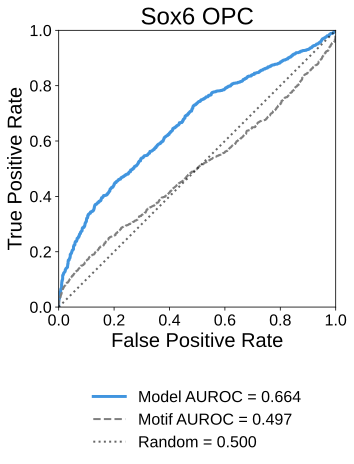

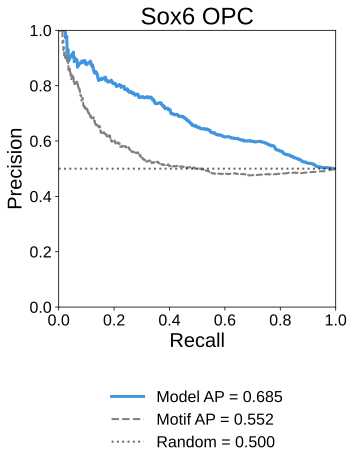

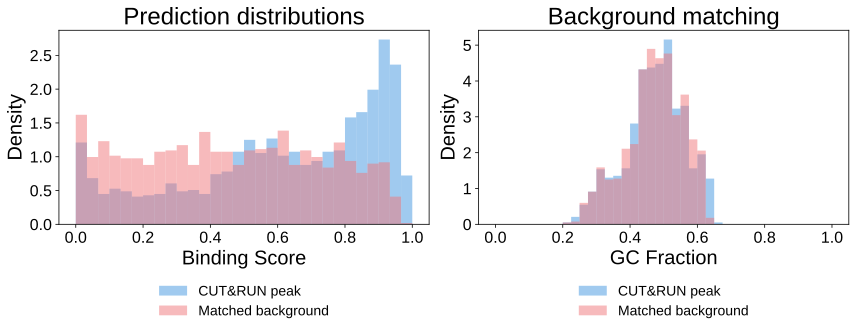

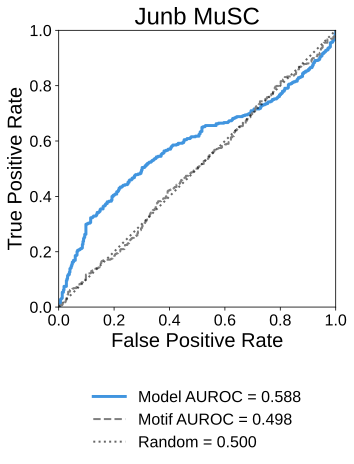

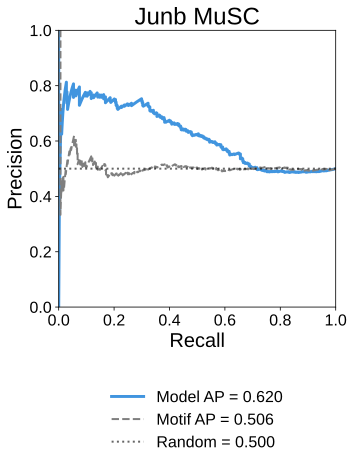

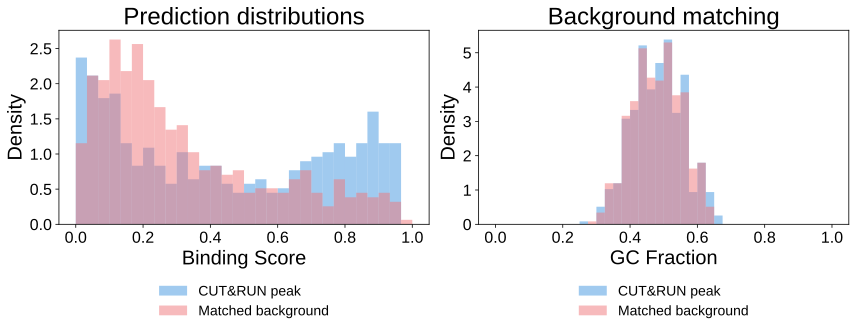

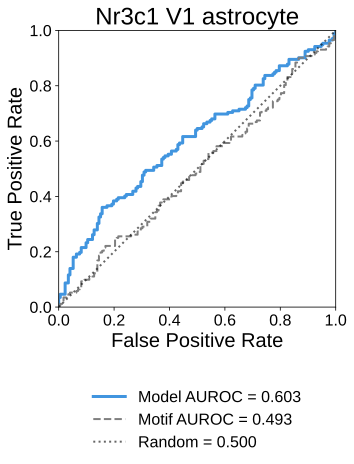

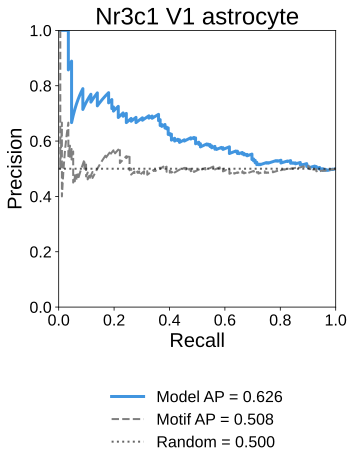

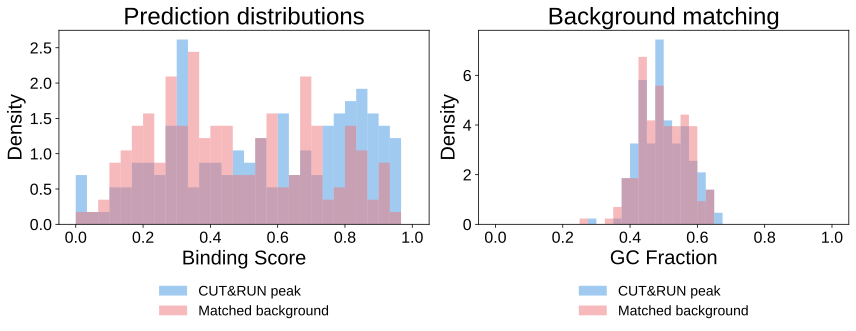

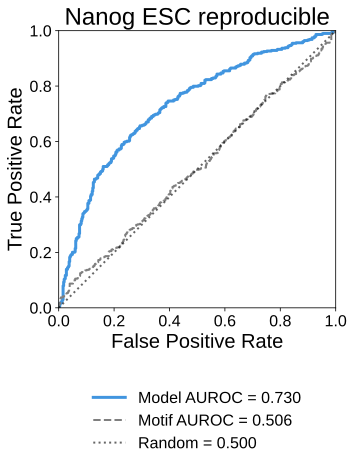

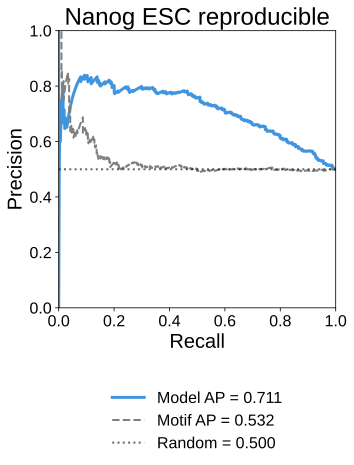

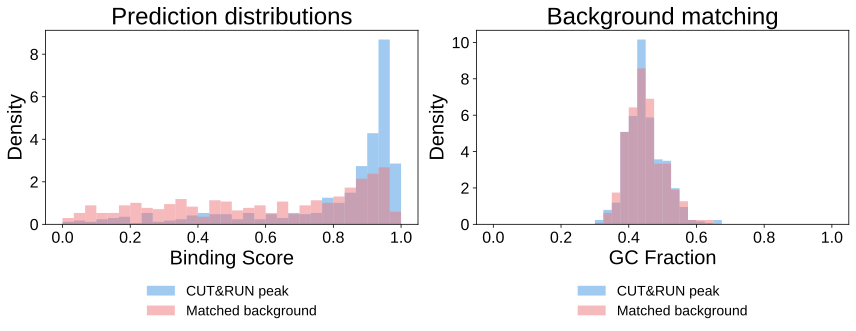

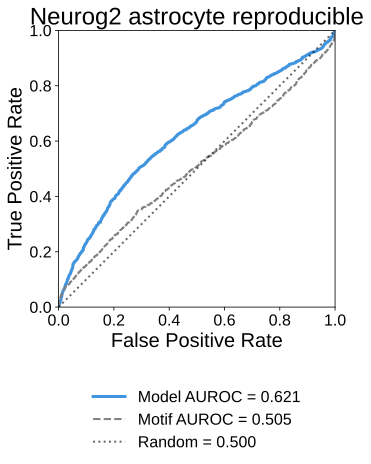

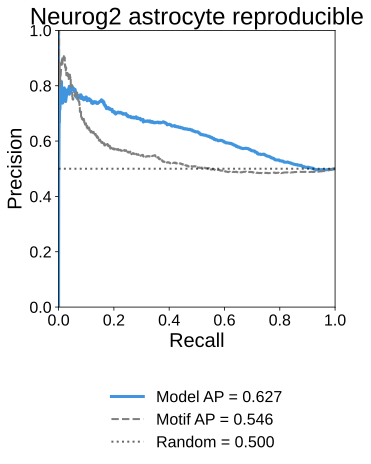

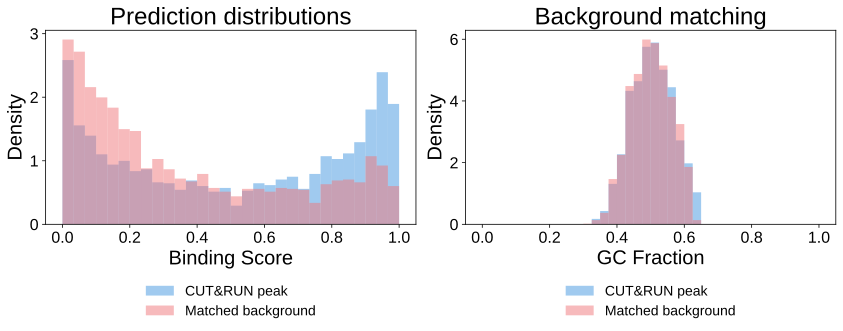

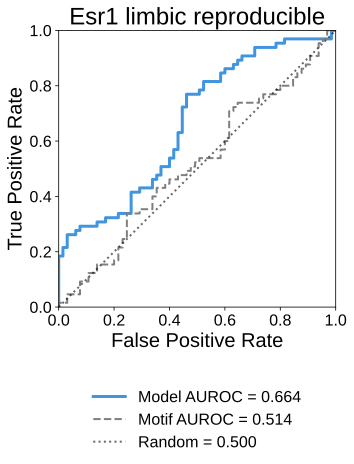

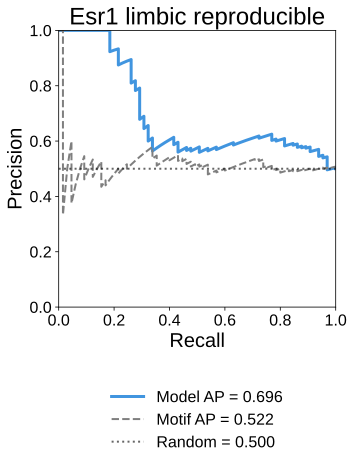

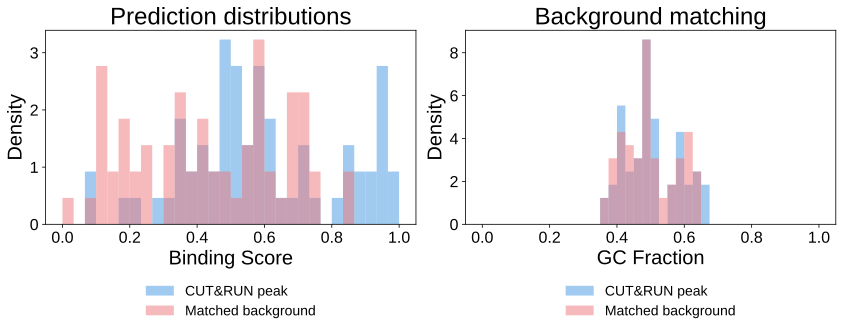

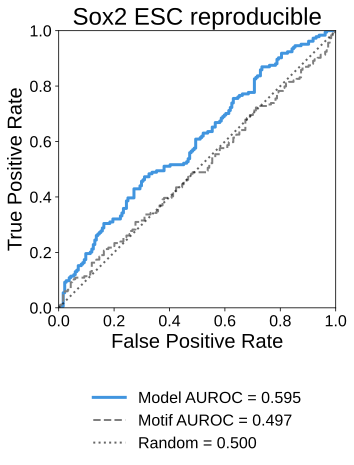

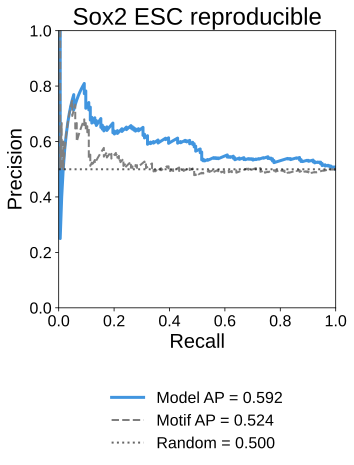

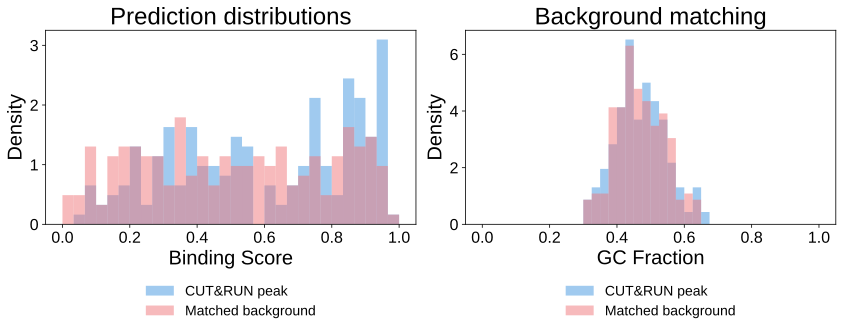

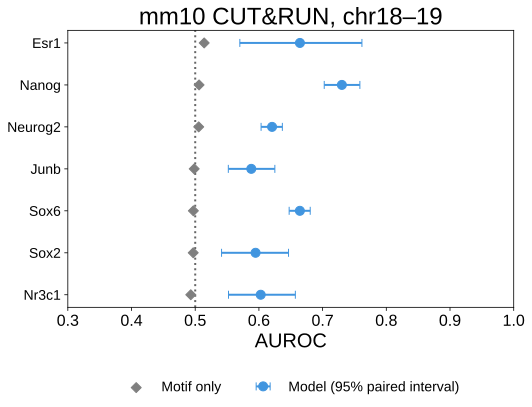

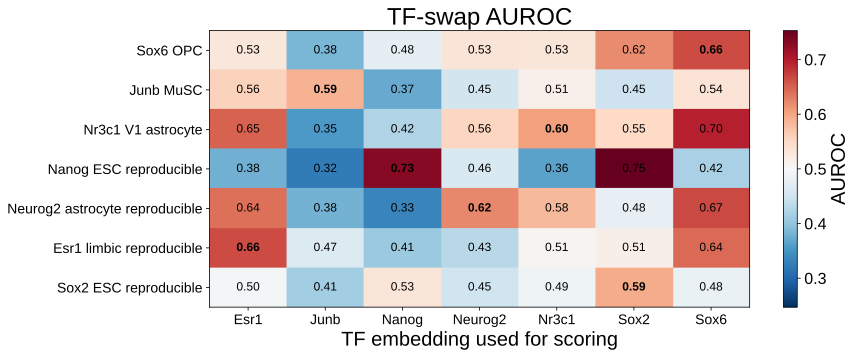

In [11]:
arial_font_path = TETHER_DIR / "fonts" / "Arial.ttf"
if arial_font_path.exists():
    font_manager.fontManager.addfont(str(arial_font_path))
    preferred_font = font_manager.FontProperties(fname=str(arial_font_path)).get_name()
else:
    preferred_font = "DejaVu Sans"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [preferred_font, "DejaVu Sans"],
    "pdf.fonttype": 42, "svg.fonttype": "none",
    "axes.titlesize": 24, "axes.labelsize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16,
})
model_color = "#4195df"
motif_color = "#7f7f7f"
background_color = "#EF767A"

def save_evaluation_figure(figure, figure_stem):
    for extension in ("png", "pdf", "svg"):
        figure.savefig(evaluation_figure_dir / f"{figure_stem}.{extension}", dpi=300, bbox_inches="tight")

metrics_by_dataset = metric_summary_df.set_index("dataset")
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    dataset_metrics = metrics_by_dataset.loc[dataset_name]
    if dataset_metrics["role"] == "replicate":
        continue
    labels = dataset_prediction_df["label"].to_numpy()
    scores = dataset_prediction_df["binding_logit"].to_numpy()
    motif_scores = dataset_prediction_df["motif_score"].to_numpy()

    roc_figure, roc_axis = plt.subplots(figsize=(6, 5))
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=model_color, lw=3,
                  label=f"Model AUROC = {dataset_metrics['auroc']:.3f}")
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, motif_scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=motif_color, lw=2, linestyle="--",
                  label=f"Motif AUROC = {dataset_metrics['motif_only_auroc']:.3f}")
    roc_axis.plot([0, 1], [0, 1], color="black", linestyle=":", lw=2, alpha=0.6, label="Random = 0.500")
    roc_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="False Positive Rate",
                 ylabel="True Positive Rate", title=dataset_name.replace("_", " "))
    roc_axis.set_aspect("equal")
    roc_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(roc_figure, f"{dataset_name}_roc")
    plt.show()
    plt.close(roc_figure)

    pr_figure, pr_axis = plt.subplots(figsize=(6, 5))
    precision, recall, _ = precision_recall_curve(labels, scores)
    pr_axis.plot(recall, precision, color=model_color, lw=3,
                 label=f"Model AP = {dataset_metrics['average_precision']:.3f}")
    precision, recall, _ = precision_recall_curve(labels, motif_scores)
    pr_axis.plot(recall, precision, color=motif_color, lw=2, linestyle="--",
                 label=f"Motif AP = {dataset_metrics['motif_only_average_precision']:.3f}")
    pr_axis.axhline(labels.mean(), color="black", linestyle=":", lw=2, alpha=0.6,
                    label=f"Random = {labels.mean():.3f}")
    pr_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
                title=dataset_name.replace("_", " "))
    pr_axis.set_aspect("equal")
    pr_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(pr_figure, f"{dataset_name}_precision_recall")
    plt.show()
    plt.close(pr_figure)

    diagnostic_figure, diagnostic_axes = plt.subplots(1, 2, figsize=(12, 5))
    for label, class_name, class_color in (
        (1, "CUT&RUN peak", model_color), (0, "Matched background", background_color),
    ):
        class_rows = dataset_prediction_df.loc[dataset_prediction_df["label"] == label]
        diagnostic_axes[0].hist(class_rows["binding_score"], bins=np.linspace(0, 1, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[1].hist(class_rows["gc_fraction"], bins=np.linspace(0, 1, 41),
                                density=True, alpha=0.5, color=class_color, label=class_name)
    diagnostic_axes[0].set(xlabel="Binding Score", ylabel="Density", title="Prediction distributions")
    diagnostic_axes[1].set(xlabel="GC Fraction", ylabel="Density", title="Background matching")
    for axis in diagnostic_axes:
        axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=14)
    diagnostic_figure.tight_layout()
    save_evaluation_figure(diagnostic_figure, f"{dataset_name}_diagnostics")
    plt.show()
    plt.close(diagnostic_figure)

# Summary: model AUROC with paired interval and the motif-only baseline for the primary and secondary
# datasets (single replicates and no-TF controls are in the tables). Rows are labeled by TF and ordered
# by motif-only AUROC (largest at the top).
summary_order = metric_summary_df.loc[~metric_summary_df["role"].isin(["replicate", "control"])].sort_values(
    "motif_only_auroc", kind="stable").reset_index(drop=True)
summary_labels = summary_order["tf_name"]
summary_figure, summary_axis = plt.subplots(figsize=(8, 0.5 * len(summary_order) + 1.5))
y_positions = np.arange(len(summary_order))
summary_axis.errorbar(
    summary_order["auroc"], y_positions,
    xerr=[summary_order["auroc"] - summary_order["auroc_ci_low"],
          summary_order["auroc_ci_high"] - summary_order["auroc"]],
    fmt="o", color=model_color, ms=9, lw=2, capsize=4, label="Model (95% paired interval)",
)
summary_axis.scatter(summary_order["motif_only_auroc"], y_positions, marker="D", s=50,
                     color=motif_color, label="Motif only", zorder=3)
summary_axis.axvline(0.5, color="black", linestyle=":", lw=2, alpha=0.6)
summary_axis.set_yticks(y_positions, summary_labels, fontsize=14)
chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
summary_axis.set(xlim=(0.3, 1.0), xlabel="AUROC", title=f"{GENOME} CUT&RUN, {chromosome_label}")
# Place the legend a fixed 0.85 inch below the axis so it clears the x label at any figure height.
axis_height_inches = summary_axis.get_position().height * summary_figure.get_figheight()
summary_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.85 / axis_height_inches),
                    frameon=False, fontsize=14, ncol=2)
save_evaluation_figure(summary_figure, "auroc_summary")
plt.show()
plt.close(summary_figure)

# Primary, secondary, and control datasets only; the full matrix, with replicates, is in tf_swap_auroc.tsv.
swap_values = tf_swap_matrix.loc[
    metrics_by_dataset.loc[tf_swap_matrix.index, "role"].to_numpy() != "replicate", EVALUATED_TFS
]
swap_figure, swap_axis = plt.subplots(figsize=(1.3 * len(EVALUATED_TFS) + 3, 0.5 * len(swap_values) + 1.5))
# Diverging scale centered on random (0.5): values below 0.5 mean the embedding ranks peaks below background.
color_half_range = max(0.25, float((swap_values - 0.5).abs().max().max()))
image = swap_axis.imshow(swap_values.to_numpy(), cmap="RdBu_r", vmin=0.5 - color_half_range,
                         vmax=0.5 + color_half_range, aspect="auto")
for (row_index, column_index), value in np.ndenumerate(swap_values.to_numpy()):
    own_tf = metrics_by_dataset.loc[swap_values.index[row_index], "tf_name"]
    weight = "bold" if EVALUATED_TFS[column_index] == own_tf else "normal"
    swap_axis.text(column_index, row_index, f"{value:.2f}", ha="center", va="center", fontsize=12, fontweight=weight)
swap_axis.set_xticks(range(len(EVALUATED_TFS)), EVALUATED_TFS, fontsize=14)
swap_axis.set_yticks(range(len(swap_values)), swap_values.index.str.replace("_", " "), fontsize=14)
swap_axis.set(xlabel="TF embedding used for scoring", title="TF-swap AUROC")
swap_figure.colorbar(image, ax=swap_axis, label="AUROC")
save_evaluation_figure(swap_figure, "tf_swap_auroc")
plt.show()
plt.close(swap_figure)

## Reproducibility record and interpretation

The run records the checkpoint, input checksums, saved split audit, embedding check, motif choice, matching rules, package versions, compute host, and Slurm job. Prediction tables keep the exact evaluation row order and DNA sequences. Download commands are in `data/CUT&RUN_data/mm10/download_instructions.txt` and `TETHER/bash_scripts/download_mm10_cutrun_additional_peaks.sh`.

Interpretation is limited to sequence discrimination for these TFs, assays, chromosomes, and backgrounds. The model receives no cell-state, accessibility, TF-expression, or cofactor measurements. A good result supports sequence-based enrichment at CUT&RUN peaks; it cannot establish cell-type-specific occupancy. The data sets differ in cell type, tissue, and replicate structure; Neurog2 is exogenous.

In [12]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

provenance_input_paths = [
    tf_dna_model_path, evaluation_windows_path,
    *sorted({cutrun_data_dir / filename for item in cutrun_dataset_definitions
             for filename in item["files"] if (cutrun_data_dir / filename).is_file()}),
    *[tf_dna_input_cache_dir / filename for filename in (
        "train_idx.pt", "val_idx.pt", "test_idx.pt", "edge_peak_idx.pt",
        "peak_id_to_idx.csv", "tf_name_to_idx.csv", "tf_masks.pt",
    )],
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    homer_background_fasta,
    *[cutrun_data_dir / filename for filename in EXTRA_PROVENANCE_FILES],
    *[cutrun_data_dir / f"{series}_family.soft.gz" for series in geo_metadata_by_series],
    Path(str(genome_fasta_path) + ".fai"),
]
run_provenance = dict(
    completed_utc=datetime.now(timezone.utc).isoformat(),
    host=socket.gethostname(),
    slurm_job_id=os.environ.get("TF_DNA_CUTRUN_BATCH_JOB_ID", os.environ.get("SLURM_JOB_ID")),
    kernel_environment_slurm_job_id=os.environ.get("SLURM_JOB_ID"),
    genome=GENOME, checkpoint=str(tf_dna_model_path), tf_dna_cache=str(tf_dna_input_cache_dir), device=str(device),
    gpu=torch.cuda.get_device_name() if device.type == "cuda" else None,
    python=platform.python_version(), torch=torch.__version__,
    numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
    matplotlib=mpl.__version__, pysam=pysam.__version__,
    chromosomes=EVALUATION_CHROMOSOMES, random_seed=RANDOM_SEED,
    window_length=DNA_WINDOW_LENGTH, gc_tolerance=GC_MATCH_TOLERANCE,
    background=f"HOMER {homer_background_fasta.name}, GC within {GC_MATCH_TOLERANCE}, without replacement per dataset",
    motif_only_score="calculate_pwm_motif_score (explore_tf_dna_model_features.ipynb), forward strand, sum over windows",
    inference_batch_size=INFERENCE_BATCH_SIZE, bootstrap_replicates=BOOTSTRAP_REPLICATES,
    score_orientation="forward genomic (primary); reverse complement reported",
    center="valid narrowPeak summit; midpoint for BED or invalid summit",
    tf_embedding_source="training cache tf_embeddings.pt with tf_masks.pt",
    embedding_check=embedding_check_df.to_dict(orient="records"),
    motifs=motif_records,
    datasets=[{key: value for key, value in item.items()} for item in cutrun_dataset_definitions],
    reference=dict(path=str(genome_fasta_path), size_bytes=genome_fasta_path.stat().st_size,
                   mtime_ns=genome_fasta_path.stat().st_mtime_ns,
                   validation=f"chromosome lengths match downloaded UCSC {GENOME} chromosome sizes"),
    file_sha256={str(path): sha256_file(path) for path in provenance_input_paths},
)
(evaluation_result_dir / "run_provenance.json").write_text(json.dumps(run_provenance, indent=2, default=str) + "\n")

chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
interpretation_lines = [
    "### Observed results",
    "",
    f"All results compare {chromosome_label} CUT&RUN peaks with 1:1 GC-matched HOMER background sequences.",
    "",
    "| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for row in metric_summary_df.itertuples(index=False):
    interpretation_lines.append(
        f"| {row.dataset} | {row.role} | {row.positive_windows:,} | "
        f"{row.auroc:.3f} ({row.auroc_ci_low:.3f}–{row.auroc_ci_high:.3f}) | {row.average_precision:.3f} | "
        f"{row.motif_only_auroc:.3f} | {row.model_minus_motif_auroc:+.3f} "
        f"({row.model_minus_motif_auroc_ci_low:+.3f} to {row.model_minus_motif_auroc_ci_high:+.3f}) |"
    )
interpretation_lines += [
    "",
    "Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. "
    "The intervals describe sampled loci and do not establish biological replicate uncertainty.",
    "",
    f"Predictions and methods records: {evaluation_result_dir}",
    f"Figures: {evaluation_figure_dir}",
]
interpretation_markdown = "\n".join(interpretation_lines)
(evaluation_result_dir / "results_summary.md").write_text(interpretation_markdown + "\n")
display(Markdown(interpretation_markdown))
genome_fasta.close()

### Observed results

All results compare chr18–19 CUT&RUN peaks with 1:1 GC-matched HOMER background sequences.

| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) |
|---|---|---:|---:|---:|---:|---:|
| Nanog_ESC_rep1 | replicate | 717 | 0.701 (0.672–0.728) | 0.702 | 0.496 | +0.204 (+0.170 to +0.238) |
| Nanog_ESC_rep2 | replicate | 1,027 | 0.723 (0.702–0.746) | 0.710 | 0.503 | +0.221 (+0.196 to +0.247) |
| Neurog2_astrocyte_rep1 | replicate | 2,202 | 0.622 (0.607–0.638) | 0.632 | 0.500 | +0.122 (+0.099 to +0.144) |
| Neurog2_astrocyte_rep2 | replicate | 4,164 | 0.613 (0.602–0.624) | 0.630 | 0.501 | +0.112 (+0.096 to +0.128) |
| Sox6_OPC | primary | 1,536 | 0.664 (0.647–0.681) | 0.685 | 0.497 | +0.167 (+0.142 to +0.196) |
| Junb_MuSC | primary | 468 | 0.588 (0.552–0.625) | 0.620 | 0.498 | +0.090 (+0.049 to +0.127) |
| Nr3c1_V1_astrocyte | primary | 172 | 0.603 (0.552–0.657) | 0.626 | 0.493 | +0.110 (+0.045 to +0.172) |
| Esr1_limbic_rep1 | replicate | 253 | 0.647 (0.602–0.698) | 0.655 | 0.501 | +0.146 (+0.097 to +0.202) |
| Esr1_limbic_rep2 | replicate | 189 | 0.629 (0.581–0.682) | 0.630 | 0.493 | +0.137 (+0.081 to +0.197) |
| Sox2_ESC_rep1 | replicate | 341 | 0.607 (0.566–0.643) | 0.607 | 0.486 | +0.121 (+0.076 to +0.163) |
| Sox2_ESC_rep2 | replicate | 287 | 0.580 (0.536–0.633) | 0.570 | 0.493 | +0.088 (+0.040 to +0.143) |
| Nanog_ESC_reproducible | primary | 504 | 0.730 (0.703–0.759) | 0.711 | 0.506 | +0.224 (+0.189 to +0.261) |
| Neurog2_astrocyte_reproducible | primary | 2,043 | 0.621 (0.603–0.637) | 0.627 | 0.505 | +0.115 (+0.092 to +0.138) |
| Esr1_limbic_reproducible | primary | 65 | 0.664 (0.570–0.762) | 0.696 | 0.514 | +0.150 (+0.043 to +0.252) |
| Sox2_ESC_reproducible | primary | 184 | 0.595 (0.541–0.646) | 0.592 | 0.497 | +0.098 (+0.039 to +0.154) |

Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. The intervals describe sampled loci and do not establish biological replicate uncertainty.

Predictions and methods records: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_testing_results/tf_dna_cutrun_mm10_mm10_3925194_epoch_21
Figures: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/tf_dna_cutrun_mm10_mm10_3925194_epoch_21

## Findings from the completed evaluation

All numbers are for chr18–19, which the saved-cache audit shows are absent from the training split (chr1–15) and the validation split (chr16–17). The background is now **HOMER synthetic background sequences** (`homer2 background -model`), one per peak with GC within 0.02, drawn without replacement. These sequences come from no genomic position. GC-only AUROC is 0.50–0.52 for every dataset, so the GC matching worked. The pool has almost no sequences with GC above 0.58, so 0–18% of the peaks in a set have no match and are dropped (Neurog2 18%, Sox6 12%, Nr3c1 and Esr1 about 10%, the others ≤ 4%). All data are CUT&RUN; CTCF, Atoh1, and Yy1 are not evaluated.

**The motif-only score from `explore_tf_dna_model_features.ipynb` does not separate peaks from background (AUROC 0.49–0.51 for every set).** That score adds the PWM probabilities of the observed bases over all 250 windows, so it mainly measures base composition, which the GC matching removes. The model − motif differences in the tables are therefore large for every set, and the order of the summary figure (motif-only AUROC) is close to random. The max log-odds scan does separate peaks from background (0.56–0.69), and every primary set passes the motif QC on it.

**Primary sets** (HOMER background):

| Set | Pairs | Model AUROC (95% interval) | Max log-odds AUROC | Genomic-background AUROC (before) | Own embedding best? |
|---|---:|---:|---:|---:|---|
| Nanog_ESC_reproducible | 504 | **0.730** (0.703–0.759) | 0.690 | 0.761 | No: Sox2 0.75 |
| Sox6_OPC | 1,536 | **0.664** (0.647–0.681) | 0.633 | 0.720 | Yes, by 0.05 |
| Esr1_limbic_reproducible | 65 | 0.664 (0.570–0.762) | 0.587 | 0.658 | Yes, by 0.02 |
| Neurog2_astrocyte_reproducible | 2,043 | 0.621 (0.603–0.637) | 0.629 | 0.627 | No: Sox6 0.67 |
| Nr3c1_V1_astrocyte | 172 | 0.603 (0.552–0.657) | 0.557 | 0.603 | No: Sox6 0.70 |
| Sox2_ESC_reproducible | 184 | 0.595 (0.541–0.646) | 0.562 | 0.638 | Yes, by 0.07 |
| Junb_MuSC | 468 | 0.588 (0.552–0.625) | 0.645 | 0.621 | Yes, by 0.03 |

**The model AUROCs are similar to, or 0.03–0.06 lower than, those with the genomic background.** The ranking of the TFs does not change: Nanog and Sox6 are highest, and Nanog, Sox6, and Sox2 are the clearest TF-specific results (the Sox2 embedding ranks Nanog peaks slightly higher, consistent with SOX2/NANOG co-binding in ES cells). Against the max log-odds scan, the model is above it for Nanog (+0.04), Sox6 (+0.03), Esr1 (+0.08), and Nr3c1 (+0.05), equal for Neurog2 and Sox2, and below it for Junb (−0.06).

**The Sox6 embedding still scores other peak sets high** (best embedding on Neurog2 and Nr3c1 peaks).

**Caveats.** HOMER sequences are synthetic; they lack genomic features such as repeats, so the model can score them differently from real genomic DNA. Dropping the most GC-rich peaks changes the peak sets slightly. Esr1, Nr3c1, and Sox2 have fewer than 200 pairs, so their intervals are wide.